In [10]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

In [2]:
train=pd.read_csv("/content/train.csv")
test=pd.read_csv("/content/test.csv")
sample_submission=pd.read_csv("/content/submission.csv")

In [3]:
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Submission template shape:", sample_submission.shape)
display(train.head())
display(test.head())
display(sample_submission.head())

Train shape: (18076, 12)
Test shape: (4520, 11)
Submission template shape: (4520, 2)


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left
0,18395,Southwest,WN 2981,San Francisco,Morning,zero,Afternoon,San Diego,Economy,1.67,32
1,11771,Southwest,WN 2526,Los Angeles,Night,zero,Night,San Jose,Economy,1.17,19
2,22326,Alaska_Airlines,AS 3359,San Jose,Morning,one,Evening,Sacramento,Business,6.13,44
3,18332,Southwest,WN 2462,San Jose,Afternoon,zero,Afternoon,Los Angeles,Economy,1.33,26
4,11021,American_Airlines,AA 6279,Sacramento,Morning,one,Afternoon,San Francisco,Economy,3.87,19


,id,price
0,18395,18395
1,11771,11771
2,22326,22326
3,18332,18332
4,11021,11021


In [6]:
display(train.info())
display(train.describe(include="all").T)
print("Missing values in train:\n", train.isna().sum())
print("Missing values in test:\n", test.isna().sum())
print("Duplicate rows in train:", train.duplicated().sum())
print("Target summary:\n", train["price"].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18076 entries, 0 to 18075
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                18076 non-null  int64  
 1   airline           18076 non-null  object 
 2   flight            18076 non-null  object 
 3   source_city       18076 non-null  object 
 4   departure_time    18076 non-null  object 
 5   stops             18076 non-null  object 
 6   arrival_time      18076 non-null  object 
 7   destination_city  18076 non-null  object 
 8   flight_class      18076 non-null  object 
 9   duration          18076 non-null  float64
 10  days_left         18076 non-null  int64  
 11  price             18076 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.7+ MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,18076.0,NaN,NaN,NaN,11308.626189,6526.337957,0.0,5668.75,11329.5,16949.5,22595.0
airline,18076,7,Alaska_Airlines,4554,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight,18076,1123,AA 6279,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN
source_city,18076,5,Los Angeles,4561,NaN,NaN,NaN,NaN,NaN,NaN,NaN
departure_time,18076,6,Morning,5144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
stops,18076,3,zero,13559,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_time,18076,6,Afternoon,4785,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination_city,18076,5,Los Angeles,4533,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flight_class,18076,2,Economy,10711,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,18076.0,NaN,NaN,NaN,2.746853,2.947519,0.87,1.47,1.63,2.0,28.65


Missing values in train:
 id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
price               0
dtype: int64
Missing values in test:
 id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
dtype: int64
Duplicate rows in train: 0
Target summary:
 count    18076.000000
mean       280.264550
std        221.965133
min          0.000000
25%        157.000000
50%        234.000000
75%        336.000000
max       8996.000000
Name: price, dtype: float64


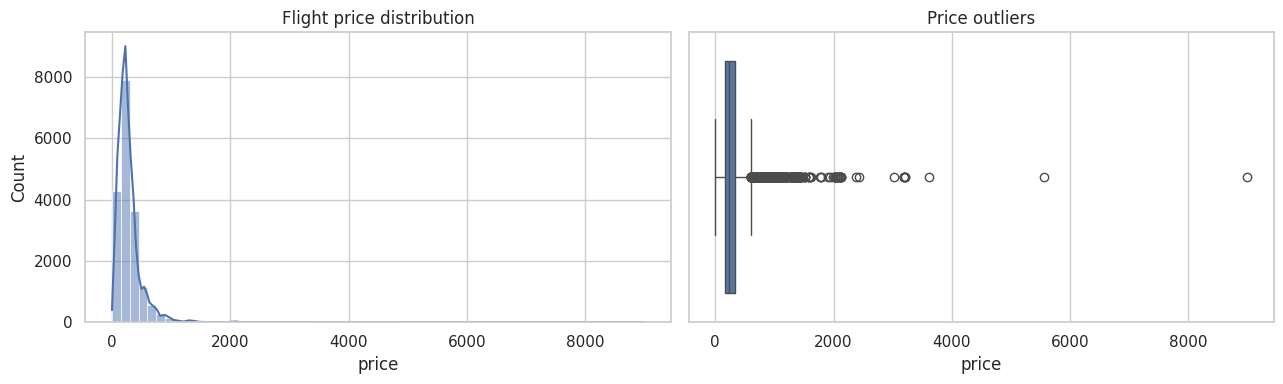

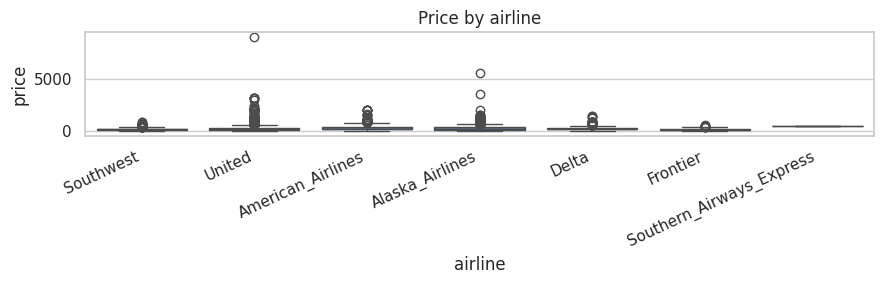

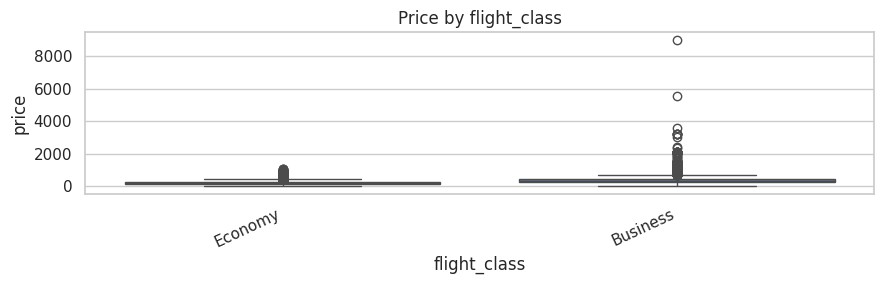

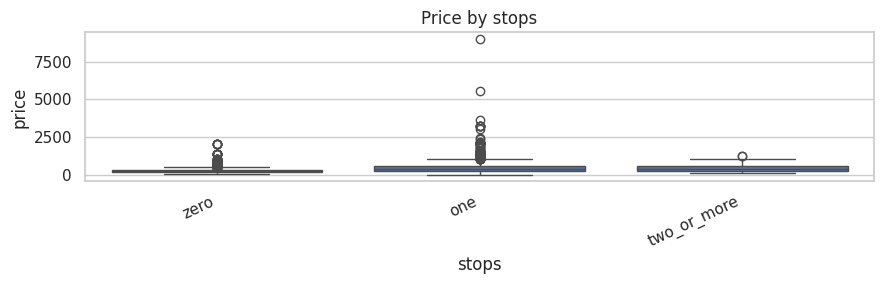

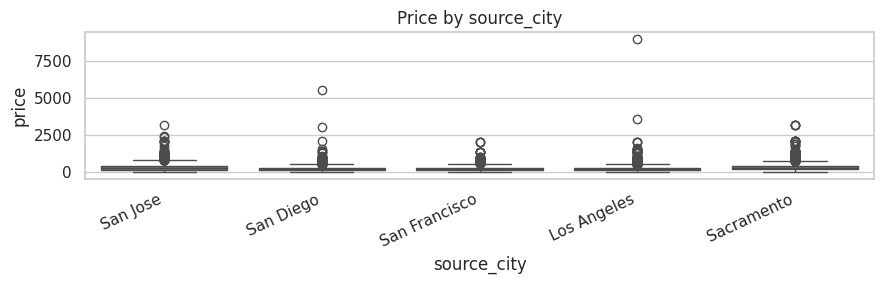

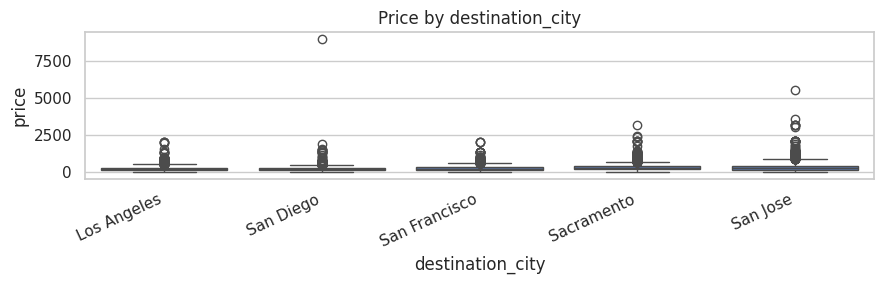

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(train["price"], bins=60, kde=True, ax=axes[0])
axes[0].set_title("Flight price distribution")
sns.boxplot(x=train["price"], ax=axes[1])
axes[1].set_title("Price outliers")
plt.tight_layout(); plt.show()

for col in ["airline", "flight_class", "stops", "source_city", "destination_city"]:
    plt.figure(figsize=(9, 3))
    sns.boxplot(data=train, x=col, y="price")
    plt.xticks(rotation=25, ha="right")
    plt.title(f"Price by {col}")
    plt.tight_layout(); plt.show()

In [8]:
TARGET = "price"

def feature_engineer(df):
    d = df.copy()
    d["route"] = d["source_city"].astype(str) + "__" + d["destination_city"].astype(str)
    d["flight_carrier_code"] = d["flight"].astype(str).str.extract(r"^\s*([A-Za-z]+)")[0].fillna("Unknown")
    d["flight_number"] = pd.to_numeric(d["flight"].astype(str).str.extract(r"(\d+)")[0], errors="coerce")
    d = d.drop(columns=["flight", "id"], errors="ignore")
    return d

X = feature_engineer(train.drop(columns=[TARGET]))
y = train[TARGET].copy()
X_test = feature_engineer(test)
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object", "category"]).columns.tolist()
print("Categorical features:", cat_cols)
print("Numerical features:", num_cols)
print("Feature matrix:", X.shape, "Test feature matrix:", X_test.shape)

Categorical features: ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'flight_class', 'route', 'flight_carrier_code']
Numerical features: ['duration', 'days_left', 'flight_number']
Feature matrix: (18076, 12) Test feature matrix: (4520, 12)


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_cols),
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), num_cols)
    ],
    remainder="drop"
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))
])

In [12]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
param_dist = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 18, 25, 32],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 3],
    "model__max_features": [0.7, 0.85, 1.0]
}
search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=6,
    scoring="r2",
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True
)
search.fit(X_train, y_train)
print("Best cross-validation R²:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)
cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(cv_results[["rank_test_score", "mean_test_score", "std_test_score", "params"]])

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best cross-validation R²: 0.708
Best parameters: {'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 3, 'model__max_features': 0.7, 'model__max_depth': 25}


,rank_test_score,mean_test_score,std_test_score,params
4,1,0.707955,0.073784,"{'model__n_estimators': 200, 'model__min_sampl..."
3,2,0.707492,0.072901,"{'model__n_estimators': 200, 'model__min_sampl..."
5,3,0.706397,0.073448,"{'model__n_estimators': 200, 'model__min_sampl..."
0,4,0.705080,0.074137,"{'model__n_estimators': 200, 'model__min_sampl..."
1,5,0.678906,0.056322,"{'model__n_estimators': 200, 'model__min_sampl..."
2,6,0.673777,0.056803,"{'model__n_estimators': 400, 'model__min_sampl..."


Validation R² : 0.6223
Validation MAE: 47.61
Validation RMSE: 145.76


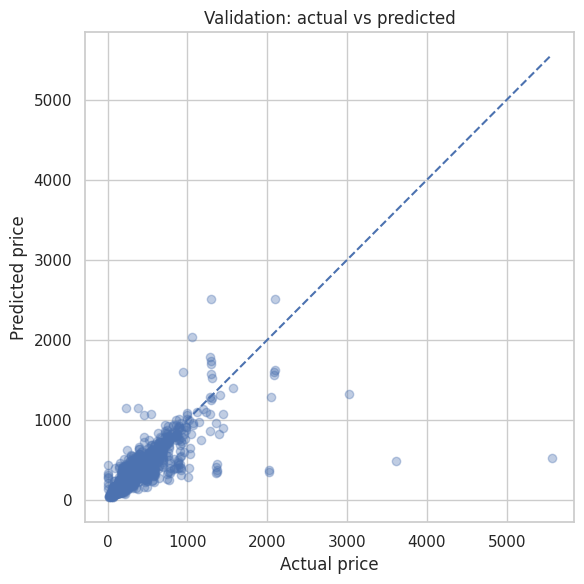

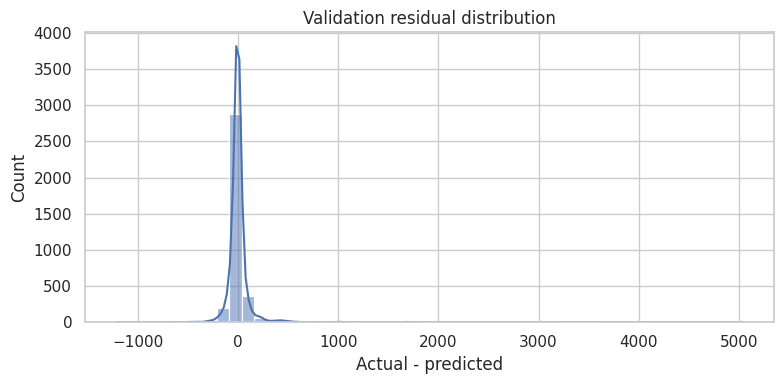

In [13]:
best_model = search.best_estimator_
val_pred = best_model.predict(X_val)
val_r2 = r2_score(y_val, val_pred)
val_mae = mean_absolute_error(y_val, val_pred)
val_rmse = mean_squared_error(y_val, val_pred) ** 0.5
print(f"Validation R² : {val_r2:.4f}")
print(f"Validation MAE: {val_mae:.2f}")
print(f"Validation RMSE: {val_rmse:.2f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_val, val_pred, alpha=0.35)
lims = [min(y_val.min(), val_pred.min()), max(y_val.max(), val_pred.max())]
plt.plot(lims, lims, "--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Validation: actual vs predicted")
plt.tight_layout(); plt.show()

residuals = y_val - val_pred
plt.figure(figsize=(8, 4))
sns.histplot(residuals, bins=50, kde=True)
plt.title("Validation residual distribution")
plt.xlabel("Actual - predicted")
plt.tight_layout(); plt.show()

,feature,importance
9,duration,0.285106
6,flight_class,0.222890
10,days_left,0.148194
11,flight_number,0.082956
8,flight_carrier_code,0.054367
3,stops,0.052081
0,airline,0.043307
7,route,0.039104
5,destination_city,0.027640
1,source_city,0.015774


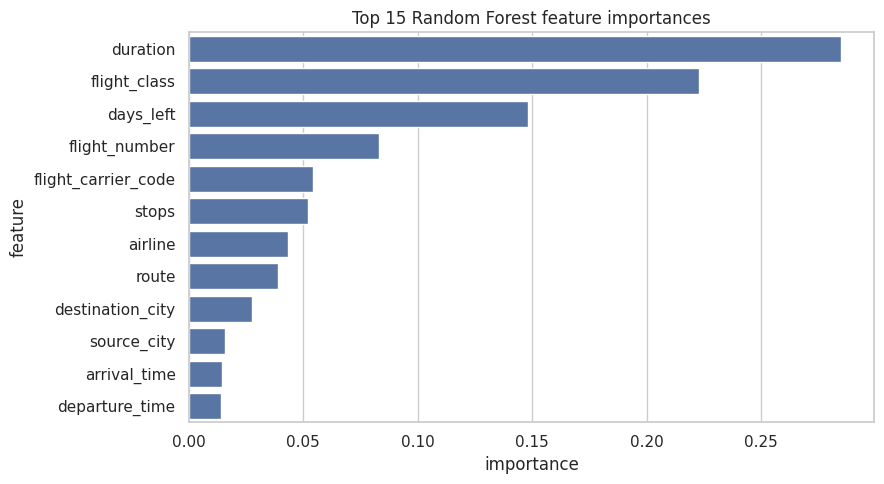

In [14]:
feature_names = cat_cols + num_cols
importances = best_model.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"feature": feature_names, "importance": importances}).sort_values("importance", ascending=False)
display(importance_df)
plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df.head(15), x="importance", y="feature")
plt.title("Top 15 Random Forest feature importances")
plt.tight_layout(); plt.show()

In [15]:
# Refit the selected pipeline on every labelled row before predicting the test set.
best_model.fit(X, y)
test_predictions = best_model.predict(X_test)

submission = pd.DataFrame({"id": test["id"], "price": test_predictions})
# Preserve the sample submission's required column order when possible.
submission = submission[["id", "price"]]
submission.to_csv("submission_random_forest.csv", index=False)
cv_results.to_csv("random_forest_cv_results.csv", index=False)
importance_df.to_csv("random_forest_feature_importance.csv", index=False)
print("Saved submission_random_forest.csv")
print("Submission shape:", submission.shape)
print(submission.head())
print("Predicted price range:", round(submission.price.min(), 2), "to", round(submission.price.max(), 2))
assert len(submission) == len(test)
assert submission["price"].notna().all()
assert submission["id"].equals(test["id"])
assert list(submission.columns) == ["id", "price"]

Saved submission_random_forest.csv
Submission shape: (4520, 2)
      id       price
0  18395   69.342394
1  11771  160.651588
2  22326  395.170823
3  18332  138.114873
4  11021  547.711789
Predicted price range: 33.64 to 2380.04
